# NB04b — Benchmark A0 vs A1 sobre TEST

**MIA-07 · Examen Final · Proyecto Crack-Seg · Etapa 4 (Integrante 4)**

Este notebook hace la **evaluación final** de la ablación *"con skip vs sin skip"* y produce las tablas y
figuras del artículo IEEE (§IV Resultados).

| Requisito del examen | Dónde se cubre |
|---|---|
| **R3** línea base | Celda 7: umbralización clásica (Otsu / adaptativa) ajustada **solo en VAL** |
| **R4** ablación, sin fuga, varias semillas | Celdas 5, 9 y 10: control de fuga, media ± desviación, Wilcoxon y bootstrap |
| **R5** interpretación | Celdas 12 y 13: análisis por grosor de fisura, tipo de error, aciertos y fallos, mapas de activación |
| **R6** costo | Celda 11: parámetros, FLOPs, inferencia en **la misma GPU**, horas de GPU de entrenamiento |

**Regla de oro (sin fuga de datos):** todas las decisiones (umbral, configuración de la línea base, qué
checkpoint usar) se toman con **VAL**. La Celda 8 **congela** esas decisiones y recién la Celda 9 toca TEST.
**No se debe volver atrás a cambiar nada después de mirar TEST.**

**Orden en Colab (GPU T4):** Celdas 1 → 14. Duración aproximada: 10–15 min (no entrena nada).

**Antes de ejecutar**, copiar en Drive:
- `resultados/NB02_EncoderDecoder/checkpoint_best.pt` (A0, pedir al Integrante 2: **falta en la carpeta actual**).
- `resultados/NB03_MiniUNet/checkpoint_best.pt` (A1, ya está).
- `resultados/NB04_Semillas/<MODELO>_seed<SEED>/checkpoint_best.pt` (las corridas del NB04a que estén listas).

El notebook detecta solo los checkpoints disponibles. Funciona con una semilla por modelo y mejora
automáticamente cuando hay más.

In [4]:
# ============================================================
# NB04b - CELDA 1: ENTORNO
# ============================================================

import sys, platform
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NOMBRE_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__)
print("Dispositivo:", device, "|", NOMBRE_GPU)
if "T4" not in NOMBRE_GPU:
    print("AVISO: se recomienda T4 (la GPU de A0) para la medición de inferencia.")
print("\nEstado: PASS")

Python: 3.13.16 | PyTorch: 2.11.0+cu130
Dispositivo: cuda | Tesla T4

Estado: PASS


In [5]:
# ============================================================
# NB04b - CELDA 2: CONFIGURACIÓN Y REGISTRO DE CORRIDAS
# ============================================================

import sys
from pathlib import Path

PRUEBA_LOCAL = False   # True solo para probar en CPU con datos simulados

BATCH_SIZE = 4
IMAGE_SIZE = 416
UMBRAL_PROTOCOLO = 0.5          # umbral fijado ANTES del experimento
SEED_REFERENCIA = 20261026      # semilla de NB02/NB03 (para las figuras)
N_BOOTSTRAP = 10000

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_BASE = Path("/content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras")
    DATOS_LOCALES = Path("/content/datos_NB04")
else:
    DRIVE_BASE = Path.cwd().resolve().parent
    DATOS_LOCALES = DRIVE_BASE / "data" / "completo"

ZIP_DATOS = DRIVE_BASE / "Entrega_Victor_Datos_Completos_v1.zip"
RUTA_DATOS = DATOS_LOCALES / "Entrega_Victor_Datos_Completos_v1"
RES = DRIVE_BASE / "resultados"
SALIDA = RES / "NB04_Benchmark"
SALIDA.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Registro de corridas: (modelo, semilla, ruta del checkpoint BEST)
# ------------------------------------------------------------
candidatos = [
    ("A0", 20261026, RES / "NB02_EncoderDecoder" / "checkpoint_best.pt"),
    ("A1", 20261026, RES / "NB03_MiniUNet" / "checkpoint_best.pt"),
]
for carpeta in sorted((RES / "NB04_Semillas").glob("A?_seed*")):
    m, s = carpeta.name.split("_seed")
    candidatos.append((m, int(s), carpeta / "checkpoint_best.pt"))

CORRIDAS = [c for c in candidatos if c[2].is_file()]

print(f"{'Modelo':<6}{'Seed':>10}  Estado")
for m, s, ruta in candidatos:
    print(f"{m:<6}{s:>10}  {'OK' if ruta.is_file() else 'FALTA -> ' + str(ruta)}")

modelos_presentes = {m for m, _, _ in CORRIDAS}
assert modelos_presentes == {"A0", "A1"}, (
    "Se necesita al menos un checkpoint de A0 y uno de A1. "
    "Si falta A0, pedir NB02_EncoderDecoder/checkpoint_best.pt al Integrante 2."
)
print("\nSalida:", SALIDA)
print("Estado: PASS -", len(CORRIDAS), "corridas disponibles.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelo      Seed  Estado
A0      20261026  OK
A1      20261026  OK
A0      20261027  OK
A0      20261028  OK
A1      20261027  OK
A1      20261028  OK

Salida: /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB04_Benchmark
Estado: PASS - 6 corridas disponibles.


In [6]:
# ============================================================
# NB04b - CELDA 3: ARQUITECTURAS A0 Y A1 + PÉRDIDA (copiadas de NB03)
#
# Se copian SIN cambios desde NB03 (Celdas 3 y 4). Si se
# modificara una sola línea, los checkpoints dejarían de cargar
# con strict=True, y eso nos avisaría del error.
# ============================================================

import torch
import torch.nn as nn


class BloqueConv(nn.Module):
    """Dos convoluciones 3x3 + ReLU (idéntico a NB02/NB03)."""

    def __init__(self, canales_entrada, canales_salida):
        super().__init__()
        self.capas = nn.Sequential(
            nn.Conv2d(canales_entrada, canales_salida, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(canales_salida, canales_salida, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.capas(x)


class EncoderDecoder(nn.Module):
    """A0: Encoder-Decoder SIN conexiones skip (NB02)."""

    def __init__(self):
        super().__init__()
        self.encoder1 = BloqueConv(3, 16)
        self.pool1 = nn.MaxPool2d(2)
        self.encoder2 = BloqueConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = BloqueConv(32, 64)
        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder1 = BloqueConv(64, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder2 = BloqueConv(32, 16)
        self.salida = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        x = self.encoder1(x)
        x = self.pool1(x)
        x = self.encoder2(x)
        x = self.pool2(x)
        x = self.bottleneck(x)
        x = self.up1(x)
        x = self.decoder1(x)
        x = self.up2(x)
        x = self.decoder2(x)
        return self.salida(x)


class MiniUNet(nn.Module):
    """A1: misma red que A0 + 2 conexiones skip por concatenación (NB03)."""

    def __init__(self):
        super().__init__()
        self.encoder1 = BloqueConv(3, 16)
        self.pool1 = nn.MaxPool2d(2)
        self.encoder2 = BloqueConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = BloqueConv(32, 64)
        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder1 = BloqueConv(64 + 32, 32)
        self.up2 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder2 = BloqueConv(32 + 16, 16)
        self.salida = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        skip1 = self.encoder1(x)
        x = self.pool1(skip1)
        skip2 = self.encoder2(x)
        x = self.pool2(skip2)
        x = self.bottleneck(x)
        x = self.up1(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.decoder1(x)
        x = self.up2(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.decoder2(x)
        return self.salida(x)


class BCEDiceLoss(nn.Module):
    """BCE + Dice (1:1), idéntica a NB02/NB03."""

    def __init__(self, smooth=1.0):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def forward(self, logits, mascaras):
        loss_bce = self.bce(logits, mascaras)
        prob = torch.sigmoid(logits)
        dims = (1, 2, 3)
        inter = torch.sum(prob * mascaras, dim=dims)
        dice = (2 * inter + self.smooth) / (
            torch.sum(prob, dim=dims) + torch.sum(mascaras, dim=dims) + self.smooth
        )
        return loss_bce + (1 - dice.mean())


def contar_parametros(red):
    return sum(p.numel() for p in red.parameters() if p.requires_grad)


# Diccionario que conecta el nombre corto con la clase.
CLASES = {"A0": EncoderDecoder, "A1": MiniUNet}
NOMBRES = {"A0": "A0 Encoder-Decoder (sin skip)", "A1": "A1 Mini U-Net (con skip)"}
ARQUITECTURA = {"A0": "EncoderDecoder_sin_skip", "A1": "MiniUNet_con_skip"}

assert contar_parametros(EncoderDecoder()) == 106753
assert contar_parametros(MiniUNet()) == 118273
print("A0:", f"{contar_parametros(EncoderDecoder()):,}", "parámetros")
print("A1:", f"{contar_parametros(MiniUNet()):,}", "parámetros")
print("\nEstado: PASS - Arquitecturas idénticas a NB02/NB03.")

A0: 106,753 parámetros
A1: 118,273 parámetros

Estado: PASS - Arquitecturas idénticas a NB02/NB03.


In [7]:
# ============================================================
# NB04b - CELDA 4: EXTRACCIÓN DEL ZIP Y LECTOR DE NICOLÁS (igual que NB03)
# ============================================================

import sys
import zipfile
import importlib.util

if not (RUTA_DATOS / "lector_pytorch.py").is_file():
    assert ZIP_DATOS.is_file(), f"No se encontró el ZIP: {ZIP_DATOS}"
    print("Extrayendo", ZIP_DATOS.name, "...")
    DATOS_LOCALES.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_DATOS, "r") as z:
        z.extractall(DATOS_LOCALES)
    print("Extracción finalizada.")

assert (RUTA_DATOS / "lector_pytorch.py").is_file(), (
    f"No se encontró lector_pytorch.py en {RUTA_DATOS}"
)

if str(RUTA_DATOS) not in sys.path:
    sys.path.insert(0, str(RUTA_DATOS))

spec = importlib.util.spec_from_file_location(
    "lector_pytorch_nb04", str(RUTA_DATOS / "lector_pytorch.py")
)
modulo_lector = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = modulo_lector
spec.loader.exec_module(modulo_lector)

# Mismos argumentos que NB02/NB03 (el lector baraja TRAIN con
# seed interna 42 y NO baraja VAL).
train_loader, val_loader = modulo_lector.make_loaders(
    RUTA_DATOS, batch_size=BATCH_SIZE, size=IMAGE_SIZE
)

if not PRUEBA_LOCAL:
    assert len(train_loader.dataset) == 3717
    assert len(val_loader.dataset) == 199

print("TRAIN:", len(train_loader.dataset), "| VAL:", len(val_loader.dataset))
print("\nEstado: PASS - Datos listos (mismas particiones que NB02/NB03).")

Extrayendo Entrega_Victor_Datos_Completos_v1.zip ...
Extracción finalizada.
TRAIN: 3717 | VAL: 199

Estado: PASS - Datos listos (mismas particiones que NB02/NB03).


In [8]:
# ============================================================
# NB04b - CELDA 5: CONJUNTO TEST + CONTROL DE FUGA DE DATOS
#
# make_loaders() de Nicolás solo devuelve TRAIN y VAL. Para TEST
# se intenta, en este orden:
#   A) Una función oficial que tú indiques (TEST_LOADER_MANUAL).
#   B) Reconstruir la MISMA clase Dataset del lector, cambiando
#      la partición "val" por "test" (usa SU preprocesamiento).
#   C) Leer los archivos de la carpeta test y elegir el
#      preprocesamiento que reproduce EXACTAMENTE el VAL oficial.
# En B y C se VERIFICA contra VAL antes de aceptar el resultado.
# ============================================================

import copy, hashlib, inspect, re
import numpy as np
import cv2
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Vía oficial: la clase FisurasDataset del lector de Nicolás acepta
# split="test" (lee listas/test.csv). Es la que se usa por defecto.
# Las estrategias B y C quedan como respaldo si el lector cambiara.
if hasattr(modulo_lector, "FisurasDataset"):
    TEST_LOADER_MANUAL = DataLoader(
        modulo_lector.FisurasDataset(RUTA_DATOS, "test", IMAGE_SIZE),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
else:
    TEST_LOADER_MANUAL = None
# Si la estrategia C no encuentra las carpetas, indicarlas a mano:
TEST_IMG_DIR, TEST_MASK_DIR = None, None

N_TEST_ESPERADO = None if PRUEBA_LOCAL else 111
EXT_IMG = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
NOMBRES_VAL = {"val", "valid", "validation", "validacion", "validación"}
NOMBRES_TEST = ["test", "Test", "TEST", "prueba"]

val_ds = val_loader.dataset

print("Funciones del lector:",
      [n for n, o in inspect.getmembers(modulo_lector, inspect.isfunction)])
print("Firma make_loaders:", inspect.signature(modulo_lector.make_loaders))
print("Clase del Dataset VAL:", type(val_ds).__name__,
      inspect.signature(type(val_ds).__init__))


def es_mascara(p):
    return re.search(r"mask|label|gt|annot", str(p).lower()) is not None


def iguales(ds_a, ds_b, n=8):
    """Compara las n primeras muestras de dos datasets."""
    for i in range(min(n, len(ds_a))):
        xa, ya, ia = ds_a[i]
        xb, yb, ib = ds_b[i]
        if ia != ib or (xa - xb).abs().max() > 2 / 255 or (ya != yb).float().mean() > 1e-3:
            return False
    return True


def sustituir_particion(valor):
    """Cambia 'val'/'valid' por 'test' en textos o rutas."""
    if isinstance(valor, str) and valor.lower() in NOMBRES_VAL:
        return ["test"]
    if isinstance(valor, (str, Path)):
        partes = Path(valor).parts
        idx = [k for k, p in enumerate(partes) if p.lower() in NOMBRES_VAL]
        if idx:
            k = idx[-1]
            return [Path(*partes[:k], t, *partes[k + 1:]) for t in NOMBRES_TEST]
    return None


# ---------------- Estrategia B ----------------
def estrategia_b():
    cls = type(val_ds)
    params = [p for p in inspect.signature(cls.__init__).parameters if p != "self"]
    base = {}
    for p in params:
        for nombre in (p, "_" + p):
            if hasattr(val_ds, nombre):
                base[p] = getattr(val_ds, nombre)
                break
    if set(base) != set(params):
        return None, f"no se pudieron leer todos los argumentos {params}"
    try:
        if not iguales(val_ds, cls(**base)):
            return None, "reconstruir VAL no reproduce el VAL oficial"
    except Exception as e:
        return None, f"error reconstruyendo VAL: {e}"
    for p, v in base.items():
        for alternativa in (sustituir_particion(v) or []):
            try:
                ds = cls(**{**base, p: type(v)(alternativa) if isinstance(v, (str, Path)) else alternativa})
                if len(ds) > 0:
                    return ds, f"argumento '{p}' -> {alternativa}"
            except Exception:
                continue
    return None, "ningún argumento contenía la partición val"


# ---------------- Estrategia C ----------------
class DatasetArchivos(Dataset):
    def __init__(self, pares, variante):
        self.pares, self.variante = pares, variante

    def __len__(self):
        return len(self.pares)

    def __getitem__(self, i):
        ruta_img, ruta_mask, ident = self.pares[i]
        lib, interp, umbral_m = self.variante
        S = IMAGE_SIZE
        if lib == "pil":
            modo = {"bilinear": Image.BILINEAR, "bicubic": Image.BICUBIC, "nearest": Image.NEAREST}[interp]
            x = np.asarray(Image.open(ruta_img).convert("RGB").resize((S, S), modo), np.float32) / 255
            m = np.asarray(Image.open(ruta_mask).convert("L").resize((S, S), Image.NEAREST))
        else:
            modo = {"bilinear": cv2.INTER_LINEAR, "area": cv2.INTER_AREA, "nearest": cv2.INTER_NEAREST}[interp]
            x = cv2.cvtColor(cv2.imread(str(ruta_img)), cv2.COLOR_BGR2RGB)
            x = cv2.resize(x, (S, S), interpolation=modo).astype(np.float32) / 255
            m = cv2.resize(cv2.imread(str(ruta_mask), cv2.IMREAD_GRAYSCALE), (S, S),
                           interpolation=cv2.INTER_NEAREST)
        y = (m > umbral_m).astype(np.float32)
        return torch.from_numpy(x).permute(2, 0, 1).contiguous(), torch.from_numpy(y)[None], ident


archivos = [p for p in RUTA_DATOS.rglob("*") if p.suffix.lower() in EXT_IMG]
por_stem = {}
for p in archivos:
    por_stem.setdefault(p.stem, []).append(p)


def localizar(ident):
    imgs = [p for p in por_stem.get(ident, []) if not es_mascara(p.relative_to(RUTA_DATOS))]
    masks = [p for s in (ident, ident + "_mask", ident + "_label") for p in por_stem.get(s, [])
             if es_mascara(p.relative_to(RUTA_DATOS))]
    return (imgs[0], masks[0]) if imgs and masks else (None, None)


def pares_de_carpeta(dir_img, dir_mask, sufijo, ext_mask):
    pares = []
    for p in sorted(dir_img.iterdir()):
        if p.suffix.lower() in EXT_IMG and not es_mascara(p.name):
            m = dir_mask / f"{p.stem}{sufijo}{ext_mask}"
            if m.is_file():
                pares.append((p, m, p.stem))
    return pares


def estrategia_c():
    ids_val = [val_ds[i][2] for i in range(min(8, len(val_ds)))]
    img0, mask0 = localizar(ids_val[0])
    if img0 is None:
        return None, "no se encontraron los archivos de VAL por su ID"
    sufijo, ext_mask = mask0.stem[len(ids_val[0]):], mask0.suffix
    pares_val = [(*localizar(i), i) for i in ids_val]
    if any(p[0] is None for p in pares_val):
        return None, "algunos IDs de VAL no tienen archivo"

    variantes = [(lib, it, um) for lib, its in (("pil", ("bilinear", "bicubic", "nearest")),
                                                  ("cv2", ("bilinear", "area", "nearest")))
                 for it in its for um in (0, 127)]
    elegida = None
    for v in variantes:
        if iguales(val_ds, DatasetArchivos(pares_val, v)):
            elegida = v
            break
    if elegida is None:
        return None, "ninguna variante reproduce el preprocesamiento de VAL"

    if TEST_IMG_DIR:
        dir_img, dir_mask = Path(TEST_IMG_DIR), Path(TEST_MASK_DIR)
    else:
        dir_img = next((d for d in (sustituir_particion(img0.parent) or []) if d.is_dir()), None)
        dir_mask = next((d for d in (sustituir_particion(mask0.parent) or []) if d.is_dir()), None)
        if dir_img is None or dir_mask is None:
            return None, "no se encontró la carpeta test (indicar TEST_IMG_DIR/TEST_MASK_DIR)"
    pares = pares_de_carpeta(dir_img, dir_mask, sufijo, ext_mask)
    return DatasetArchivos(pares, elegida), f"carpeta {dir_img} | preprocesamiento {elegida}"


# ---------------- Selección ----------------
if TEST_LOADER_MANUAL is not None:
    test_loader, origen = TEST_LOADER_MANUAL, "A) oficial: FisurasDataset(split='test') de lector_pytorch"
else:
    test_ds, motivo = estrategia_b()
    origen = "B) " + motivo
    if test_ds is None:
        print("Estrategia B descartada:", motivo)
        test_ds, motivo = estrategia_c()
        origen = "C) " + motivo
    assert test_ds is not None, (
        "No se pudo construir TEST automáticamente: " + motivo +
        "\nPedir a Nicolás la función o la ruta de TEST y usar TEST_LOADER_MANUAL."
    )
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print("\nTEST construido con:", origen)
print("Imágenes TEST:", len(test_loader.dataset))
if N_TEST_ESPERADO:
    assert len(test_loader.dataset) == N_TEST_ESPERADO, "TEST no tiene 111 imágenes"

x, y, ids = next(iter(test_loader))
assert tuple(x.shape[1:]) == (3, IMAGE_SIZE, IMAGE_SIZE)
assert set(y.unique().tolist()) <= {0.0, 1.0}

# ------------------------------------------------------------
# CONTROL DE FUGA: ¿hay imágenes de TEST repetidas en TRAIN/VAL?
#   1) Mismo archivo (hash MD5 idéntico).
#   2) Misma foto de origen: los nombres de Roboflow son
#      "<origen>.rf.<hash>", y las versiones aumentadas de una
#      foto comparten el <origen>.
# ------------------------------------------------------------

def particion_de(p):
    for parte in p.relative_to(RUTA_DATOS).parts:
        low = parte.lower()
        if low in NOMBRES_VAL: return "val"
        if low in {t.lower() for t in NOMBRES_TEST}: return "test"
        if low == "train": return "train"
    return None

imagenes_por_part = {"train": [], "val": [], "test": []}
for p in archivos:
    if not es_mascara(p.relative_to(RUTA_DATOS)):
        k = particion_de(p)
        if k:
            imagenes_por_part[k].append(p)

ids_test = [test_loader.dataset[i][2] for i in range(len(test_loader.dataset))]
origen_de = lambda s: s.split(".rf.")[0]
md5 = lambda p: hashlib.md5(p.read_bytes()).hexdigest()

fuga = {}
if imagenes_por_part["train"]:
    org_test = {origen_de(i) for i in ids_test}
    for k in ("train", "val"):
        org_k = {origen_de(p.stem) for p in imagenes_por_part[k]}
        fuga[f"origen_comun_test_{k}"] = len(org_test & org_k)
    h_test = {md5(p) for p in imagenes_por_part["test"]}
    h_otros = {md5(p) for k in ("train", "val") for p in imagenes_por_part[k]}
    fuga["archivos_identicos_test_vs_train_val"] = len(h_test & h_otros)
    print("\nControl de fuga:", fuga)
    if any(fuga.values()):
        print("ATENCIÓN: hay posible fuga. Reportarlo en el artículo y consultar con Nicolás.")
    else:
        print("Sin coincidencias: TEST es independiente de TRAIN y VAL.")
else:
    print("\nNo se identificaron carpetas por partición; control de fuga omitido.")

print("\nEstado: PASS - TEST listo (aún NO se ha evaluado).")

Funciones del lector: ['load_pair', 'make_loaders', 'read_manifest']
Firma make_loaders: (root, batch_size=4, size=None, seed=42)
Clase del Dataset VAL: FisurasDataset (self, root, split='train', size=None)

TEST construido con: A) oficial: FisurasDataset(split='test') de lector_pytorch
Imágenes TEST: 111

Control de fuga: {'origen_comun_test_train': 0, 'origen_comun_test_val': 0, 'archivos_identicos_test_vs_train_val': 0}
Sin coincidencias: TEST es independiente de TRAIN y VAL.

Estado: PASS - TEST listo (aún NO se ha evaluado).


In [9]:
# ============================================================
# NB04b - CELDA 6: FUNCIONES DE EVALUACIÓN Y CARGA DE MODELOS
#
# Para cada imagen guardamos los conteos de píxeles:
#   TP = fisura bien detectada      FP = falsa alarma
#   FN = fisura no detectada
# Con ellos se calculan todas las métricas, de dos formas:
#   - GLOBAL: sumando píxeles de todo el conjunto (como NB02/03).
#   - POR IMAGEN: promedio de las métricas de cada imagen.
# No se usa accuracy: con ~95 % de fondo, un modelo que no
# detecta nada tendría 95 % de accuracy.
#
# Dice con tolerancia de 2 px: un píxel predicho cuenta como
# acierto si hay fisura real a <= 2 px (las etiquetas de fisuras
# finas son imprecisas en el borde).
# ============================================================

import numpy as np
import pandas as pd
import torch.nn.functional as F
from IPython.display import display

TOL = 2

def cargar_modelo(m, ruta):
    estado = torch.load(ruta, map_location=device, weights_only=False)
    red = CLASES[m]().to(device)
    red.load_state_dict(estado["model_state_dict"], strict=True)
    red.eval()
    return red, estado


def metricas_desde_conteos(tp, fp, fn):
    return {
        "dice": 2 * tp / max(2 * tp + fp + fn, 1),
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
    }


@torch.inference_mode()
def evaluar(predictor, loader):
    """predictor(x) -> tensor booleano Bx1xHxW. Devuelve una fila por imagen."""
    filas = []
    for x, y, ids in loader:
        x, y = x.to(device), y.to(device)
        pred = predictor(x)
        real = y >= 0.5
        dims = (1, 2, 3)
        tp = (pred & real).sum(dims)
        fp = (pred & ~real).sum(dims)
        fn = (~pred & real).sum(dims)
        # Tolerancia: dilatar con max-pool de ventana (2*TOL+1).
        k = 2 * TOL + 1
        real_d = F.max_pool2d(real.float(), k, 1, TOL) > 0
        pred_d = F.max_pool2d(pred.float(), k, 1, TOL) > 0
        tp_p_tol = (pred & real_d).sum(dims)   # predichos cerca de fisura real
        tp_r_tol = (real & pred_d).sum(dims)   # reales cerca de predicción
        for i in range(x.size(0)):
            filas.append({
                "id": ids[i], "tp": int(tp[i]), "fp": int(fp[i]), "fn": int(fn[i]),
                "gt_px": int(real[i].sum()), "pred_px": int(pred[i].sum()),
                "tp_p_tol": int(tp_p_tol[i]), "tp_r_tol": int(tp_r_tol[i]),
                "total_px": int(real[i].numel()),
            })
    df = pd.DataFrame(filas)
    # Métricas por imagen. Convención: si la máscara real y la
    # predicha están vacías, la imagen se cuenta como acierto (1).
    vacia = (df.gt_px == 0) & (df.pred_px == 0)
    df["dice"] = np.where(vacia, 1.0, 2 * df.tp / (2 * df.tp + df.fp + df.fn).clip(lower=1))
    df["iou"] = np.where(vacia, 1.0, df.tp / (df.tp + df.fp + df.fn).clip(lower=1))
    df["precision"] = df.tp / df.pred_px.clip(lower=1)
    df["recall"] = df.tp / df.gt_px.clip(lower=1)
    p_t = df.tp_p_tol / df.pred_px.clip(lower=1)
    r_t = df.tp_r_tol / df.gt_px.clip(lower=1)
    df["dice_tol2"] = np.where(vacia, 1.0, 2 * p_t * r_t / (p_t + r_t).clip(lower=1e-9))
    df["frac_fisura"] = df.gt_px / df.total_px
    return df


def resumen_global(df):
    tp, fp, fn = df.tp.sum(), df.fp.sum(), df.fn.sum()
    r = metricas_desde_conteos(tp, fp, fn)
    p_t = df.tp_p_tol.sum() / max(df.pred_px.sum(), 1)
    r_t = df.tp_r_tol.sum() / max(df.gt_px.sum(), 1)
    r["dice_tol2"] = 2 * p_t * r_t / max(p_t + r_t, 1e-9)
    r["dice_medio_img"] = df.dice.mean()
    r["iou_medio_img"] = df.iou.mean()
    return r


def predictor_red(red, umbral):
    return lambda x: torch.sigmoid(red(x)) >= umbral


# Cargar todas las corridas y verificar que reproducen su Dice de VAL.
MODELOS_CARGADOS = {}
print(f"{'Corrida':<16}{'Epoch BEST':>11}{'Val Dice (ckpt)':>17}{'GPU entrenamiento':>22}")
for m, s, ruta in CORRIDAS:
    red, estado = cargar_modelo(m, ruta)
    hist = estado.get("historial") or []
    reg = next((r for r in hist if r["epoch"] == estado["epoch"]), {})
    MODELOS_CARGADOS[(m, s)] = {"red": red, "estado": estado, "val_dice_ckpt": reg.get("val_dice")}
    vd = reg.get("val_dice")
    print(f"{m + '_seed' + str(s):<16}{estado['epoch']:>11}"
          f"{(f'{vd:.4f}' if vd is not None else 'n/d'):>17}{str(estado.get('gpu', 'n/d')):>22}")

print("\nEstado: PASS - Funciones listas y", len(MODELOS_CARGADOS), "modelos cargados.")

Corrida          Epoch BEST  Val Dice (ckpt)     GPU entrenamiento
A0_seed20261026          13           0.7290                   n/d
A1_seed20261026          21           0.7351             NVIDIA L4
A0_seed20261027          16           0.7273              Tesla T4
A0_seed20261028          16           0.7282              Tesla T4
A1_seed20261027          12           0.7268              Tesla T4
A1_seed20261028          13           0.7281              Tesla T4

Estado: PASS - Funciones listas y 6 modelos cargados.


In [10]:
# ============================================================
# NB04b - CELDA 7: DECISIONES TOMADAS SOLO CON VALIDACIÓN
#
#  7.1 Verificación: cada checkpoint reproduce su Dice de VAL.
#  7.2 Umbral óptimo en VAL (análisis SECUNDARIO; el principal
#      usa 0.5, fijado antes del experimento).
#  7.3 Línea base clásica (R3): umbralización de intensidad.
#      Las fisuras son más OSCURAS que el concreto, así que se
#      buscan píxeles oscuros (THRESH_BINARY_INV). Se prueban
#      varias configuraciones y se elige la mejor EN VAL.
# ============================================================

import itertools, time

# ---- 7.1 y 7.2 ----
UMBRALES = np.round(np.arange(0.20, 0.81, 0.05), 2)
filas_val, UMBRAL_OPT = [], {}

with torch.inference_mode():
    for (m, s), info in MODELOS_CARGADOS.items():
        conteos = {u: np.zeros(3) for u in UMBRALES}
        for x, y, _ in val_loader:
            prob = torch.sigmoid(info["red"](x.to(device)))
            real = y.to(device) >= 0.5
            for u in UMBRALES:
                pred = prob >= u
                conteos[u] += [int((pred & real).sum()), int((pred & ~real).sum()), int((~pred & real).sum())]
        dices = {u: metricas_desde_conteos(*conteos[u])["dice"] for u in UMBRALES}
        u_opt = max(dices, key=dices.get)
        UMBRAL_OPT[(m, s)] = float(u_opt)
        d05 = dices[0.5]
        if info["val_dice_ckpt"] is not None and not PRUEBA_LOCAL:
            assert abs(d05 - info["val_dice_ckpt"]) < 1e-3, f"{m} seed {s} no reproduce su Dice de VAL"
        filas_val.append({"modelo": m, "seed": s, "val_dice_u05": d05,
                          "umbral_opt_val": u_opt, "val_dice_u_opt": dices[u_opt]})

df_val = pd.DataFrame(filas_val)
print("7.1-7.2  Validación (reproducción y umbral óptimo):")
display(df_val.round(4))

# ---- 7.3 Línea base clásica ----

def a_gris_uint8(x):
    g = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).cpu().numpy()
    return (g * 255).clip(0, 255).astype(np.uint8)


def segmentar_clasico(gris, cfg):
    g = cv2.GaussianBlur(gris, (5, 5), 0)
    if cfg["metodo"] == "otsu":
        _, b = cv2.threshold(g, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    else:
        b = cv2.adaptiveThreshold(g, 1, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY_INV, cfg["bloque"], cfg["C"])
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    if cfg["area_min"] > 0:   # eliminar manchas pequeñas
        n, etiq, stats, _ = cv2.connectedComponentsWithStats(b, 8)
        grandes = np.zeros(n, bool)
        grandes[1:] = stats[1:, cv2.CC_STAT_AREA] >= cfg["area_min"]
        b = grandes[etiq].astype(np.uint8)
    return b


def predictor_clasico(cfg):
    def f(x):
        gris = a_gris_uint8(x)
        pred = np.stack([segmentar_clasico(g, cfg) for g in gris])[:, None]
        return torch.from_numpy(pred).to(x.device) > 0
    return f


configs = [{"metodo": "otsu", "bloque": None, "C": None, "area_min": a} for a in (0, 100)]
configs += [{"metodo": "adaptativo", "bloque": b, "C": c, "area_min": a}
            for b, c, a in itertools.product((15, 31, 51), (5, 10, 15), (0, 100))]

filas_base = []
t0 = time.time()
for cfg in configs:
    r = resumen_global(evaluar(predictor_clasico(cfg), val_loader))
    filas_base.append({**cfg, **{k: r[k] for k in ("dice", "iou", "precision", "recall")}})
df_base_val = pd.DataFrame(filas_base).sort_values("dice", ascending=False)
CFG_BASE = {k: df_base_val.iloc[0][k] for k in ("metodo", "bloque", "C", "area_min")}
for k in ("bloque", "C", "area_min"):
    if CFG_BASE[k] is not None and not pd.isna(CFG_BASE[k]):
        CFG_BASE[k] = int(CFG_BASE[k])

print(f"\n7.3  Línea base clásica: {len(configs)} configuraciones en VAL ({time.time() - t0:.0f} s). Top 5:")
display(df_base_val.head(5).round(4))
print("Configuración elegida (solo con VAL):", CFG_BASE)
df_val.to_csv(SALIDA / "VAL_umbral_y_reproduccion.csv", index=False)
df_base_val.to_csv(SALIDA / "VAL_busqueda_linea_base.csv", index=False)
print("\nEstado: PASS - Decisiones tomadas con VAL.")

7.1-7.2  Validación (reproducción y umbral óptimo):


,modelo,seed,val_dice_u05,umbral_opt_val,val_dice_u_opt
0,A0,20261026,0.7290,0.60,0.7291
1,A1,20261026,0.7351,0.30,0.7355
2,A0,20261027,0.7273,0.20,0.7300
3,A0,20261028,0.7282,0.20,0.7297
4,A1,20261027,0.7268,0.25,0.7280
5,A1,20261028,0.7281,0.45,0.7283



7.3  Línea base clásica: 20 configuraciones en VAL (56 s). Top 5:


,metodo,bloque,C,area_min,dice,iou,precision,recall
19,adaptativo,51.0,15.0,100,0.5704,0.3990,0.5937,0.5489
11,adaptativo,31.0,10.0,100,0.5596,0.3885,0.6013,0.5234
13,adaptativo,31.0,15.0,100,0.5373,0.3673,0.7306,0.4248
17,adaptativo,51.0,10.0,100,0.5292,0.3598,0.4586,0.6254
3,adaptativo,15.0,5.0,100,0.5116,0.3437,0.6693,0.4141


Configuración elegida (solo con VAL): {'metodo': 'adaptativo', 'bloque': 51, 'C': 15, 'area_min': 100}

Estado: PASS - Decisiones tomadas con VAL.


In [11]:
# ============================================================
# NB04b - CELDA 8: CONGELAR DECISIONES (protocolo sin fuga)
#
# A partir de aquí NADA se ajusta. Si después de ver TEST se
# cambia un umbral o una configuración, TEST deja de ser una
# evaluación independiente (fuga de información).
# ============================================================

import json
from datetime import datetime

DECISIONES = {
    "fecha": datetime.now().isoformat(),
    "umbral_principal": UMBRAL_PROTOCOLO,
    "umbral_optimo_val_por_corrida": {f"{m}_seed{s}": u for (m, s), u in UMBRAL_OPT.items()},
    "linea_base": CFG_BASE,
    "corridas": [f"{m}_seed{s}" for m, s, _ in CORRIDAS],
    "checkpoint": "BEST por Val Loss (definido en NB02/NB03)",
}
with open(SALIDA / "DECISIONES_CONGELADAS.json", "w", encoding="utf-8") as f:
    json.dump(DECISIONES, f, indent=4, ensure_ascii=False, default=str)

DECISIONES_CONGELADAS = True
print(json.dumps(DECISIONES, indent=2, ensure_ascii=False, default=str))
print("\nEstado: PASS - Decisiones congeladas y guardadas ANTES de mirar TEST.")

{
  "fecha": "2026-11-03T16:53:21.975967",
  "umbral_principal": 0.5,
  "umbral_optimo_val_por_corrida": {
    "A0_seed20261026": 0.6,
    "A1_seed20261026": 0.3,
    "A0_seed20261027": 0.2,
    "A0_seed20261028": 0.2,
    "A1_seed20261027": 0.25,
    "A1_seed20261028": 0.45
  },
  "linea_base": {
    "metodo": "adaptativo",
    "bloque": 51,
    "C": 15,
    "area_min": 100
  },
  "corridas": [
    "A0_seed20261026",
    "A1_seed20261026",
    "A0_seed20261027",
    "A0_seed20261028",
    "A1_seed20261027",
    "A1_seed20261028"
  ],
  "checkpoint": "BEST por Val Loss (definido en NB02/NB03)"
}

Estado: PASS - Decisiones congeladas y guardadas ANTES de mirar TEST.


In [12]:
# ============================================================
# NB04b - CELDA 9: EVALUACIÓN FINAL EN TEST (una sola vez)
# ============================================================

assert DECISIONES_CONGELADAS, "Ejecutar primero la Celda 8."

tablas = []
for (m, s), info in MODELOS_CARGADOS.items():
    for tipo, u in (("u=0.5 (principal)", UMBRAL_PROTOCOLO), ("u óptimo VAL", UMBRAL_OPT[(m, s)])):
        df = evaluar(predictor_red(info["red"], u), test_loader)
        df["modelo"], df["seed"], df["umbral_tipo"], df["umbral"] = m, s, tipo, u
        tablas.append(df)

df_b = evaluar(predictor_clasico(CFG_BASE), test_loader)
df_b["modelo"], df_b["seed"], df_b["umbral_tipo"], df_b["umbral"] = "Base", 0, "u=0.5 (principal)", np.nan
tablas.append(df_b)

df_test = pd.concat(tablas, ignore_index=True)
df_test.to_csv(SALIDA / "TEST_metricas_por_imagen.csv", index=False, encoding="utf-8-sig")

# Métricas globales por corrida.
filas = []
for (m, s, tipo), g in df_test.groupby(["modelo", "seed", "umbral_tipo"]):
    filas.append({"modelo": m, "seed": s, "umbral_tipo": tipo, **resumen_global(g)})
df_runs = pd.DataFrame(filas)
df_runs.to_csv(SALIDA / "TEST_metricas_por_corrida.csv", index=False, encoding="utf-8-sig")

PRINCIPAL = df_test[df_test.umbral_tipo == "u=0.5 (principal)"]
print("Imágenes TEST:", PRINCIPAL.id.nunique(), "| máscaras vacías:",
      int((PRINCIPAL.drop_duplicates("id").gt_px == 0).sum()))
display(df_runs.round(4))
print("\nEstado: PASS - TEST evaluado.")

Imágenes TEST: 111 | máscaras vacías: 0


,modelo,seed,umbral_tipo,dice,iou,precision,recall,dice_tol2,dice_medio_img,iou_medio_img
0,A0,20261026,u óptimo VAL,0.7067,0.5464,0.7004,0.7131,0.8720,0.6878,0.5467
1,A0,20261026,u=0.5 (principal),0.7062,0.5458,0.6931,0.7198,0.8719,0.6870,0.5454
2,A0,20261027,u óptimo VAL,0.7033,0.5424,0.7152,0.6918,0.8664,0.6899,0.5481
3,A0,20261027,u=0.5 (principal),0.7010,0.5397,0.7417,0.6646,0.8671,0.6885,0.5477
4,A0,20261028,u óptimo VAL,0.7043,0.5436,0.6999,0.7088,0.8659,0.6923,0.5494
5,A0,20261028,u=0.5 (principal),0.7037,0.5429,0.7253,0.6834,0.8672,0.6923,0.5504
6,A1,20261026,u óptimo VAL,0.7132,0.5542,0.7108,0.7156,0.8781,0.6912,0.5506
7,A1,20261026,u=0.5 (principal),0.7130,0.5540,0.7248,0.7016,0.8771,0.6919,0.5523
8,A1,20261027,u óptimo VAL,0.7073,0.5472,0.7090,0.7057,0.8678,0.6914,0.5512
9,A1,20261027,u=0.5 (principal),0.7066,0.5463,0.7284,0.6860,0.8682,0.6913,0.5518



Estado: PASS - TEST evaluado.


In [13]:
# ============================================================
# NB04b - CELDA 10: TABLA PRINCIPAL Y PRUEBAS ESTADÍSTICAS (R4)
#
# - Media ± desviación entre semillas (si hay >= 2 por modelo).
# - Wilcoxon pareado: compara A1 vs A0 IMAGEN POR IMAGEN (el
#   Dice de cada imagen, promediado entre semillas). Pregunta:
#   ¿la diferencia es consistente o es ruido? p < 0.05 -> real.
# - Bootstrap: remuestrea las 111 imágenes 10 000 veces y da un
#   intervalo de confianza del 95 % para la diferencia de Dice
#   global. Si el intervalo contiene el 0, no hay diferencia clara.
# ============================================================

from scipy.stats import wilcoxon

NOMBRE_FILA = {"Base": "Línea base clásica", **NOMBRES}
METRICAS = ["dice", "iou", "precision", "recall", "dice_tol2", "dice_medio_img"]


def tabla_media_std(df_r, tipo):
    filas = []
    for m in ("Base", "A0", "A1"):
        g = df_r[(df_r.modelo == m) & (df_r.umbral_tipo == tipo)]
        if g.empty:
            continue
        fila = {"Modelo": NOMBRE_FILA[m], "Semillas": len(g)}
        for k in METRICAS:
            fila[k] = (f"{g[k].mean():.4f} ± {g[k].std(ddof=1):.4f}" if len(g) > 1
                       else f"{g[k].mean():.4f}")
        filas.append(fila)
    return pd.DataFrame(filas)


tabla_principal = tabla_media_std(df_runs, "u=0.5 (principal)")
tabla_umbral_opt = tabla_media_std(df_runs[df_runs.modelo != "Base"], "u óptimo VAL")
print("TABLA PRINCIPAL - TEST (umbral 0.5):")
display(tabla_principal)
print("\nTabla secundaria - TEST con umbral óptimo de VAL:")
display(tabla_umbral_opt)

# --- Comparación pareada A1 vs A0 ---
P = PRINCIPAL[PRINCIPAL.modelo.isin(["A0", "A1"])]
d_img = P.groupby(["modelo", "id"]).dice.mean().unstack(0)        # Dice por imagen (media semillas)
dif = d_img["A1"] - d_img["A0"]
w = wilcoxon(d_img["A1"], d_img["A0"]) if (dif != 0).any() else None

# Bootstrap del Dice GLOBAL (conteos sumados sobre semillas).
cnt = P.groupby(["modelo", "id"])[["tp", "fp", "fn"]].sum()
A0c, A1c = cnt.loc["A0"].loc[d_img.index].values, cnt.loc["A1"].loc[d_img.index].values
rng = np.random.default_rng(0)
dice_g = lambda c: 2 * c[:, 0] / np.maximum(2 * c[:, 0] + c[:, 1] + c[:, 2], 1)
idx = rng.integers(0, len(d_img), size=(N_BOOTSTRAP, len(d_img)))
delta_boot = dice_g(A1c[idx].sum(1)) - dice_g(A0c[idx].sum(1))
delta_obs = dice_g(A1c.sum(0, keepdims=True))[0] - dice_g(A0c.sum(0, keepdims=True))[0]
ic = np.percentile(delta_boot, [2.5, 97.5])

# Diferencia por semilla emparejada (misma semilla en A0 y A1).
R = df_runs[df_runs.umbral_tipo == "u=0.5 (principal)"].pivot(index="seed", columns="modelo", values="dice")
R = R.dropna(subset=["A0", "A1"]) if {"A0", "A1"} <= set(R.columns) else R
delta_semillas = (R["A1"] - R["A0"]).round(4).to_dict()

ESTADISTICA = {
    "imagenes_test": int(len(d_img)),
    "delta_dice_global_A1_menos_A0": float(delta_obs),
    "ic95_bootstrap": [float(ic[0]), float(ic[1])],
    "delta_dice_medio_por_imagen": float(dif.mean()),
    "imagenes_donde_A1_gana": int((dif > 0).sum()),
    "imagenes_donde_A0_gana": int((dif < 0).sum()),
    "wilcoxon_estadistico": float(w.statistic) if w else None,
    "wilcoxon_p": float(w.pvalue) if w else None,
    "delta_dice_por_semilla": delta_semillas,
}
print("\nCOMPARACIÓN A1 - A0 (TEST):")
for k, v in ESTADISTICA.items():
    print(f"  {k}: {v}")

if ESTADISTICA["wilcoxon_p"] is not None:
    sig = ESTADISTICA["wilcoxon_p"] < 0.05 and not (ic[0] <= 0 <= ic[1])
    print("\nLectura:", "diferencia ESTADÍSTICAMENTE SIGNIFICATIVA." if sig else
          "NO hay evidencia suficiente de diferencia (p >= 0.05 o el IC contiene 0).")

tabla_principal.to_csv(SALIDA / "TABLA_principal_TEST.csv", index=False, encoding="utf-8-sig")
tabla_umbral_opt.to_csv(SALIDA / "TABLA_umbral_opt_TEST.csv", index=False, encoding="utf-8-sig")
print("\nEstado: PASS")

TABLA PRINCIPAL - TEST (umbral 0.5):


,Modelo,Semillas,dice,iou,precision,recall,dice_tol2,dice_medio_img
0,Línea base clásica,1,0.5206,0.3519,0.5217,0.5195,0.6441,0.5230
1,A0 Encoder-Decoder (sin skip),3,0.7036 ± 0.0026,0.5428 ± 0.0030,0.7200 ± 0.0248,0.6892 ± 0.0281,0.8687 ± 0.0028,0.6892 ± 0.0027
2,A1 Mini U-Net (con skip),3,0.7079 ± 0.0046,0.5478 ± 0.0056,0.7188 ± 0.0135,0.6974 ± 0.0100,0.8712 ± 0.0051,0.6898 ± 0.0031



Tabla secundaria - TEST con umbral óptimo de VAL:


,Modelo,Semillas,dice,iou,precision,recall,dice_tol2,dice_medio_img
0,A0 Encoder-Decoder (sin skip),3,0.7048 ± 0.0017,0.5441 ± 0.0020,0.7051 ± 0.0087,0.7046 ± 0.0112,0.8681 ± 0.0034,0.6900 ± 0.0023
1,A1 Mini U-Net (con skip),3,0.7082 ± 0.0047,0.5482 ± 0.0056,0.7064 ± 0.0061,0.7099 ± 0.0051,0.8714 ± 0.0058,0.6895 ± 0.0031



COMPARACIÓN A1 - A0 (TEST):
  imagenes_test: 111
  delta_dice_global_A1_menos_A0: 0.004145940523908598
  ic95_bootstrap: [-0.0010530978369141602, 0.009005584097114269]
  delta_dice_medio_por_imagen: 0.0005240074037271495
  imagenes_donde_A1_gana: 65
  imagenes_donde_A0_gana: 46
  wilcoxon_estadistico: 2679.0
  wilcoxon_p: 0.20686448640671518
  delta_dice_por_semilla: {20261026: 0.0068, 20261027: 0.0055, 20261028: 0.0003}

Lectura: NO hay evidencia suficiente de diferencia (p >= 0.05 o el IC contiene 0).

Estado: PASS


In [14]:
# ============================================================
# NB04b - CELDA 11: COSTO COMPUTACIONAL (R6)
#
# - Parámetros y FLOPs: se cuentan con "hooks" (funciones que
#   se ejecutan al pasar por cada capa). FLOPs ~ 2 x MACs.
# - Inferencia: A0 y A1 en ESTA MISMA GPU, con calentamiento
#   y torch.cuda.synchronize() (la GPU trabaja en paralelo a
#   Python; sin sincronizar, el cronómetro mentiría).
# - Entrenamiento: se lee del historial de cada corrida. Solo se
#   comparan tiempos medidos en la MISMA GPU.
# ============================================================

def contar_macs(red):
    macs = []
    def hook(mod, entrada, salida):
        k = mod.kernel_size[0] * mod.kernel_size[1] * (mod.in_channels // mod.groups)
        macs.append(salida.numel() * k)
    hs = [c.register_forward_hook(hook) for c in red.modules() if isinstance(c, nn.Conv2d)]
    with torch.inference_mode():
        red(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
    for h in hs:
        h.remove()
    return sum(macs)


import gc

def limpiar_gpu():
    gc.collect()
    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()


@torch.inference_mode()
def tiempo_una_pasada(red, x):
    """ms por imagen de UNA pasada (sincronizada con la GPU)."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    red(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) * 1000 / x.size(0)


@torch.inference_mode()
def memoria_propia_mb(red, x):
    """Memoria EXTRA que usa una pasada (descuenta lo ya ocupado en la GPU)."""
    if device.type != "cuda":
        return np.nan
    limpiar_gpu()
    base = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    red(x)
    torch.cuda.synchronize()
    return (torch.cuda.max_memory_allocated() - base) / 1024**2


# Medición justa: los dos modelos se ALTERNAN (A0, A1, A0, A1...) en
# varias rondas, para que ninguno cargue con el calentamiento de la
# GPU ni con cambios de frecuencia del reloj durante la prueba.
rondas, rep, calent = (2, 5, 2) if PRUEBA_LOCAL else (5, 40, 20)
redes, semillas_ref = {}, {}
for m in ("A0", "A1"):
    s = SEED_REFERENCIA if (m, SEED_REFERENCIA) in MODELOS_CARGADOS else \
        next(s for (mm, s) in MODELOS_CARGADOS if mm == m)
    redes[m], semillas_ref[m] = MODELOS_CARGADOS[(m, s)]["red"], s

limpiar_gpu()
tiempos = {(m, l): [] for m in redes for l in (1, BATCH_SIZE)}
for l in (1, BATCH_SIZE):
    x = torch.rand(l, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    for m in redes:                       # calentamiento de ambos
        for _ in range(calent):
            tiempo_una_pasada(redes[m], x)
    for _ in range(rondas):
        for m in redes:
            tiempos[(m, l)] += [tiempo_una_pasada(redes[m], x) for _ in range(rep)]
    del x

filas = []
for m, red in redes.items():
    x4 = torch.rand(BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    mem4 = memoria_propia_mb(red, x4)
    del x4
    t1, t4 = np.array(tiempos[(m, 1)]), np.array(tiempos[(m, BATCH_SIZE)])
    filas.append({"Modelo": NOMBRES[m], "Parámetros": contar_parametros(red),
                  "GFLOPs (416²)": 2 * contar_macs(red) / 1e9,
                  "ms/img lote 1 (mediana)": np.median(t1), "ms/img lote 1 (p90)": np.percentile(t1, 90),
                  f"ms/img lote {BATCH_SIZE} (mediana)": np.median(t4),
                  f"ms/img lote {BATCH_SIZE} (p90)": np.percentile(t4, 90),
                  f"Memoria de activaciones lote {BATCH_SIZE} (MB)": mem4,
                  "Peso checkpoint (MB)": next(r for mm, ss, r in CORRIDAS
                                               if mm == m and ss == semillas_ref[m]).stat().st_size / 1024**2})
df_costo = pd.DataFrame(filas).set_index("Modelo").T
df_costo["A1 / A0"] = df_costo.iloc[:, 1] / df_costo.iloc[:, 0]
print("Costo de inferencia medido en:", NOMBRE_GPU)
display(df_costo.round(3))

# Entrenamiento. Se lee checkpoint_LAST (tiene el historial completo;
# el BEST se guardó en la mejor epoch y su historial está cortado).
# NB02 no guardó el nombre de la GPU: se registra según su informe.
GPU_DECLARADA = {("A0", 20261026): "Tesla T4 (declarada en NB02)"}
filas = []
for (m, s, ruta) in CORRIDAS:
    ruta_last = ruta.with_name("checkpoint_last.pt")
    e = (torch.load(ruta_last, map_location="cpu", weights_only=False)
         if ruta_last.is_file() else MODELOS_CARGADOS[(m, s)]["estado"])
    if not ruta_last.is_file():
        print(f"AVISO: falta {ruta_last}; el costo de {m}_seed{s} queda incompleto.")
    h = pd.DataFrame(e.get("historial") or [])
    filas.append({"modelo": m, "seed": s, "gpu": e.get("gpu") or GPU_DECLARADA.get((m, s), "n/d"),
                  "epochs": len(h) if len(h) else np.nan,
                  "epoch_best": MODELOS_CARGADOS[(m, s)]["estado"]["epoch"],
                  "s_por_epoch": h.tiempo_epoch_seg.mean() if "tiempo_epoch_seg" in h else np.nan,
                  "horas_gpu": e.get("tiempo_acumulado_seg", np.nan) / 3600,
                  "memoria_pico_entrenamiento_mb": h.memoria_gpu_pico_mb.max() if "memoria_gpu_pico_mb" in h else np.nan})
df_entren = pd.DataFrame(filas).sort_values(["gpu", "modelo", "seed"])
print("\nCosto de entrenamiento por corrida (comparar solo dentro de la misma GPU):")
display(df_entren.round(3))
print("Horas de GPU totales del proyecto (estas corridas):", round(df_entren.horas_gpu.sum(), 2))

df_costo.to_csv(SALIDA / "COSTO_inferencia.csv", encoding="utf-8-sig")
df_entren.to_csv(SALIDA / "COSTO_entrenamiento.csv", index=False, encoding="utf-8-sig")
print("\nEstado: PASS")

Costo de inferencia medido en: Tesla T4


Modelo,A0 Encoder-Decoder (sin skip),A1 Mini U-Net (con skip),A1 / A0
Parámetros,106753.000,118273.000,1.108
GFLOPs (416²),8.129,9.724,1.196
ms/img lote 1 (mediana),7.568,10.508,1.389
ms/img lote 1 (p90),7.696,10.712,1.392
ms/img lote 4 (mediana),13.651,11.388,0.834
ms/img lote 4 (p90),13.801,11.540,0.836
Memoria de activaciones lote 4 (MB),1267.570,277.266,0.219
Peso checkpoint (MB),1.264,1.398,1.106



Costo de entrenamiento por corrida (comparar solo dentro de la misma GPU):


,modelo,seed,gpu,epochs,epoch_best,s_por_epoch,horas_gpu,memoria_pico_entrenamiento_mb
1,A1,20261026,NVIDIA L4,28,21,59.476,0.463,661.443
2,A0,20261027,Tesla T4,23,16,159.781,1.021,1650.257
3,A0,20261028,Tesla T4,23,16,164.744,1.053,1650.257
4,A1,20261027,Tesla T4,19,12,162.638,0.858,2136.944
5,A1,20261028,Tesla T4,20,13,163.490,0.908,2136.944
0,A0,20261026,Tesla T4 (declarada en NB02),20,13,156.652,0.870,NaN


Horas de GPU totales del proyecto (estas corridas): 5.17

Estado: PASS


12.1  Dice medio por imagen según grosor (% de píxeles de fisura):


,% fisura mín,% fisura máx,imágenes,A0,A1,Base,A1 - A0
Finas (tercio inferior),0.34,1.20,37,0.6470,0.6467,0.5091,-0.0004
Medias,1.25,2.19,37,0.7611,0.7581,0.5922,-0.0030
Anchas (tercio superior),2.25,5.86,37,0.6596,0.6645,0.4678,0.0049


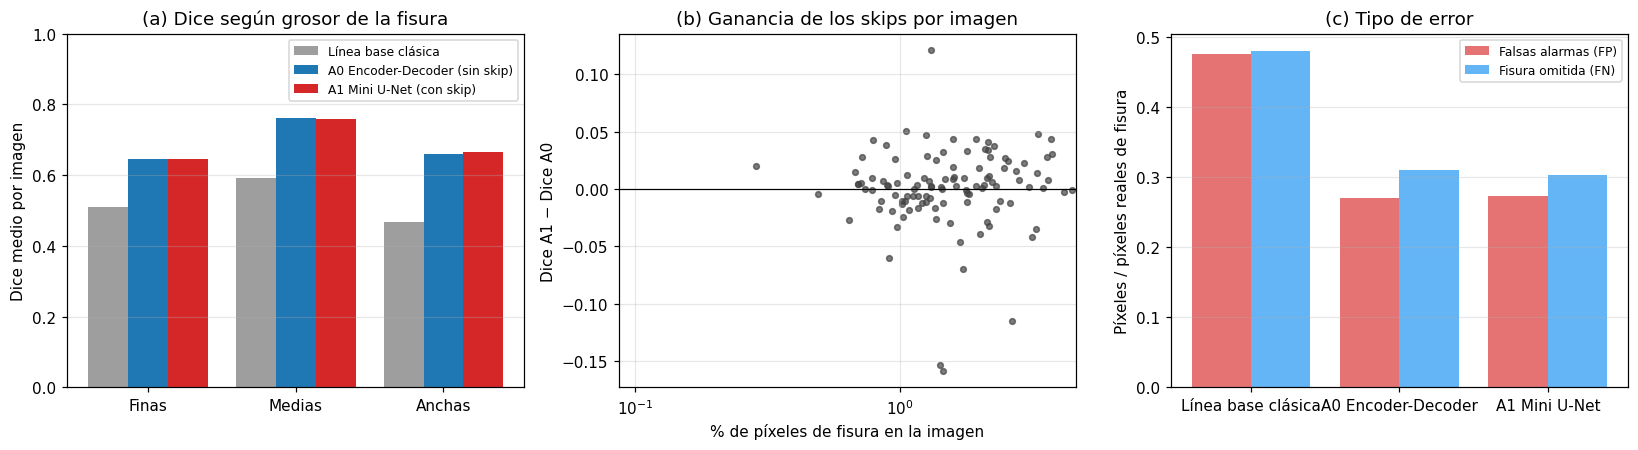

12.3  Errores relativos a los píxeles reales de fisura:


,fp,fn
modelo,,
Base,0.476,0.481
A0,0.270,0.311
A1,0.273,0.303



Estado: PASS


In [15]:
# ============================================================
# NB04b - CELDA 12: ANÁLISIS DE ERRORES (R5)
#
# Hipótesis: los skips llevan al decoder detalle de alta
# resolución que el encoder pierde al reducir la imagen, así que
# deberían ayudar más en fisuras FINAS (pocos píxeles).
#  12.1 Dice por grosor de fisura (terciles de % de píxeles de fisura).
#  12.2 Diferencia A1-A0 por imagen vs % de fisura.
#  12.3 Tipo de error: ¿falsas alarmas (FP) u omisiones (FN)?
# ============================================================

import matplotlib.pyplot as plt

COLOR = {"Base": "#9e9e9e", "A0": "#1f77b4", "A1": "#d62728"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})

por_img = PRINCIPAL.groupby(["modelo", "id"]).agg(dice=("dice", "mean"),
                                                  frac=("frac_fisura", "first")).reset_index()
frac = por_img.drop_duplicates("id").set_index("id").frac
con_fisura = frac[frac > 0]
terciles = pd.qcut(con_fisura.rank(method="first"), 3, labels=["Finas (tercio inferior)", "Medias", "Anchas (tercio superior)"])
por_img["grupo"] = por_img.id.map(terciles)
tabla_grupos = por_img.dropna(subset=["grupo"]).pivot_table(index="grupo", columns="modelo",
                                                            values="dice", aggfunc="mean", observed=True)
tabla_grupos["A1 - A0"] = tabla_grupos["A1"] - tabla_grupos["A0"]
lims = con_fisura.groupby(terciles, observed=True).agg(["min", "max", "count"])
lims[["min", "max"]] = (100 * lims[["min", "max"]]).round(2)
lims.columns = ["% fisura mín", "% fisura máx", "imágenes"]
print("12.1  Dice medio por imagen según grosor (% de píxeles de fisura):")
display(pd.concat([lims, tabla_grupos.round(4)], axis=1))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
xg = np.arange(len(tabla_grupos))
for k, m in enumerate(["Base", "A0", "A1"]):
    if m in tabla_grupos:
        ax[0].bar(xg + (k - 1) * 0.27, tabla_grupos[m], 0.27, label=NOMBRE_FILA[m], color=COLOR[m])
ax[0].set_xticks(xg, [str(g).split(" (")[0] for g in tabla_grupos.index])
ax[0].set_ylabel("Dice medio por imagen"); ax[0].set_ylim(0, 1)
ax[0].set_title("(a) Dice según grosor de la fisura"); ax[0].legend(fontsize=8)
ax[0].grid(axis="y", alpha=0.3)

d_img_ = d_img.join(frac.rename("frac"))
ax[1].scatter(100 * d_img_.frac, d_img_.A1 - d_img_.A0, s=14, alpha=0.7, color="#444")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xscale("symlog", linthresh=0.5)
ax[1].set_xlabel("% de píxeles de fisura en la imagen"); ax[1].set_ylabel("Dice A1 − Dice A0")
ax[1].set_title("(b) Ganancia de los skips por imagen"); ax[1].grid(alpha=0.3)

err = PRINCIPAL.groupby("modelo")[["tp", "fp", "fn"]].sum()
err = err.div(err.tp + err.fn, axis=0)      # normalizado por píxeles reales de fisura
orden = [m for m in ("Base", "A0", "A1") if m in err.index]
xe = np.arange(len(orden))
ax[2].bar(xe - 0.2, err.loc[orden, "fp"], 0.4, label="Falsas alarmas (FP)", color="#e57373")
ax[2].bar(xe + 0.2, err.loc[orden, "fn"], 0.4, label="Fisura omitida (FN)", color="#64b5f6")
ax[2].set_xticks(xe, [NOMBRE_FILA[m].split(" (")[0] for m in orden])
ax[2].set_ylabel("Píxeles / píxeles reales de fisura")
ax[2].set_title("(c) Tipo de error"); ax[2].legend(fontsize=8); ax[2].grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(SALIDA / "FIG_analisis_errores.png", bbox_inches="tight")
plt.show()

print("12.3  Errores relativos a los píxeles reales de fisura:")
display(err.loc[orden, ["fp", "fn"]].round(3))
tabla_grupos.to_csv(SALIDA / "TABLA_dice_por_grosor.csv", encoding="utf-8-sig")
print("\nEstado: PASS")

In [16]:
# ============================================================
# NB04b - CELDA 13: EJEMPLOS VISUALES Y MAPAS DE ACTIVACIÓN (R5)
#
# Casos elegidos de forma SISTEMÁTICA (no a mano):
#   las 4 imágenes donde A1 más gana a A0 y las 4 donde más pierde.
# Colores: verde = acierto (TP), rojo = falsa alarma (FP),
#          azul = fisura omitida (FN).
# Mapa de activación: promedio de |activaciones| a la salida de
# decoder2 (16 canales, resolución completa). Muestra si la red
# conserva el trazo fino de la fisura antes de la capa final.
# ============================================================

ganan = dif.sort_values(ascending=False).index[:4].tolist()
pierden = dif.sort_values().index[:4].tolist()
pos = {ident: i for i, ident in enumerate(ids_test)}
red0 = MODELOS_CARGADOS[(("A0", SEED_REFERENCIA) if ("A0", SEED_REFERENCIA) in MODELOS_CARGADOS
                         else next(k for k in MODELOS_CARGADOS if k[0] == "A0"))]["red"]
red1 = MODELOS_CARGADOS[(("A1", SEED_REFERENCIA) if ("A1", SEED_REFERENCIA) in MODELOS_CARGADOS
                         else next(k for k in MODELOS_CARGADOS if k[0] == "A1"))]["red"]


def superposicion(img, pred, real):
    out = img.copy() * 0.6
    out[pred & real] = [0.1, 0.85, 0.1]
    out[pred & ~real] = [0.95, 0.1, 0.1]
    out[~pred & real] = [0.1, 0.4, 1.0]
    return out


@torch.inference_mode()
def predecir(red, x):
    return (torch.sigmoid(red(x[None].to(device)))[0, 0] >= UMBRAL_PROTOCOLO).cpu().numpy()


def figura_casos(lista, titulo, archivo):
    fig, ax = plt.subplots(len(lista), 4, figsize=(13, 3.2 * len(lista)))
    for f, ident in enumerate(lista):
        x, y, _ = test_loader.dataset[pos[ident]]
        img = x.permute(1, 2, 0).numpy()
        real = y[0].numpy() > 0.5
        p0, p1 = predecir(red0, x), predecir(red1, x)
        dd = lambda p: 2 * (p & real).sum() / max(p.sum() + real.sum(), 1)
        paneles = [(img, f"{ident[:14]}… | fisura {100 * real.mean():.2f} %"),
                   (real, "Máscara real"),
                   (superposicion(img, p0, real), f"A0 sin skip | Dice {dd(p0):.3f}"),
                   (superposicion(img, p1, real), f"A1 Mini U-Net | Dice {dd(p1):.3f}")]
        for c, (dato, t) in enumerate(paneles):
            ax[f, c].imshow(dato, cmap="gray" if dato.ndim == 2 else None)
            ax[f, c].set_title(t, fontsize=9); ax[f, c].axis("off")
    fig.suptitle(titulo + "   (verde = TP, rojo = FP, azul = FN)\n"
                 "Selección por Dice medio entre semillas; se muestran los modelos de la semilla de referencia.",
                 y=1.01, fontsize=10)
    fig.tight_layout()
    fig.savefig(SALIDA / archivo, bbox_inches="tight")
    plt.show()


figura_casos(ganan, "Casos donde los skips MÁS ayudan", "FIG_casos_A1_gana.png")
figura_casos(pierden, "Casos donde los skips MÁS perjudican", "FIG_casos_A1_pierde.png")

# --- Mapas de activación de decoder2 ---
def activacion_decoder2(red, x):
    guardado = {}
    h = red.decoder2.register_forward_hook(lambda m, i, o: guardado.setdefault("a", o))
    with torch.inference_mode():
        red(x[None].to(device))
    h.remove()
    return guardado["a"][0].abs().mean(0).cpu().numpy()

fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for f, ident in enumerate([ganan[0], pierden[0]]):
    x, y, _ = test_loader.dataset[pos[ident]]
    ax[f, 0].imshow(x.permute(1, 2, 0).numpy()); ax[f, 0].set_title("Imagen")
    for c, (red, nombre) in enumerate([(red0, "A0 sin skip"), (red1, "A1 Mini U-Net")], start=1):
        ax[f, c].imshow(activacion_decoder2(red, x), cmap="magma")
        ax[f, c].set_title(f"{nombre}: |activación| decoder2")
    for a in ax[f]:
        a.axis("off")
fig.tight_layout()
fig.savefig(SALIDA / "FIG_activaciones_decoder2.png", bbox_inches="tight")
plt.show()
print("Estado: PASS")

Output hidden; open in https://colab.research.google.com to view.

In [17]:
# ============================================================
# NB04b - CELDA 14: EXPORTACIÓN PARA EL ARTÍCULO IEEE
# ============================================================

RESUMEN = {
    "fecha": datetime.now().isoformat(),
    "gpu_benchmark": NOMBRE_GPU,
    "test_origen": origen,
    "imagenes_test": int(len(ids_test)),
    "control_fuga": fuga,
    "decisiones_congeladas": DECISIONES,
    "tabla_principal": tabla_principal.to_dict(orient="records"),
    "estadistica_A1_vs_A0": ESTADISTICA,
    "costo_inferencia": df_costo.round(4).to_dict(),
    "dice_por_grosor": tabla_grupos.round(4).to_dict(),
}
with open(SALIDA / "NB04_Resumen_Benchmark.json", "w", encoding="utf-8") as f:
    json.dump(RESUMEN, f, indent=4, ensure_ascii=False, default=str)

# Tablas en LaTeX (para pegar en el artículo IEEE).
with open(SALIDA / "TABLAS_latex.tex", "w", encoding="utf-8") as f:
    for nombre, t in [("Resultados en TEST (umbral 0.5)", tabla_principal),
                      ("Costo computacional", df_costo.round(3)),
                      ("Dice por grosor de fisura", tabla_grupos.round(4))]:
        f.write(f"% {nombre}\n")
        try:
            f.write(t.to_latex(index=t is not tabla_principal, escape=True))
        except Exception as e:
            f.write(f"% to_latex no disponible: {e}\n")
        f.write("\n")

print("Archivos generados en", SALIDA)
for p in sorted(SALIDA.iterdir()):
    print(f"  {p.name:<38} {p.stat().st_size / 1024:8.1f} KB")
print("\nEstado: PASS - Benchmark completo.")

Archivos generados en /content/drive/MyDrive/MIA-Grupo3/MIA-07_DL/ExFinal_Fisuras/resultados/NB04_Benchmark
  COSTO_entrenamiento.csv                     0.6 KB
  COSTO_inferencia.csv                        0.6 KB
  DECISIONES_CONGELADAS.json                  0.7 KB
  FIG_activaciones_decoder2.png            2969.7 KB
  FIG_analisis_errores.png                  159.9 KB
  FIG_casos_A1_gana.png                    4335.4 KB
  FIG_casos_A1_pierde.png                  4111.9 KB
  NB04_Resumen_Benchmark.json                 4.6 KB
  TABLAS_latex.tex                            1.5 KB
  TABLA_dice_por_grosor.csv                   0.3 KB
  TABLA_principal_TEST.csv                    0.4 KB
  TABLA_umbral_opt_TEST.csv                   0.3 KB
  TEST_metricas_por_corrida.csv               2.1 KB
  TEST_metricas_por_imagen.csv              319.4 KB
  VAL_busqueda_linea_base.csv                 2.0 KB
  VAL_umbral_y_reproduccion.csv               0.4 KB

Estado: PASS - Benchmark completo.
